# ID2222 Homework 2
## A-Priori 频繁项集和关联规则

这个 Notebook 用来解释、测试和运行 `apriori.py`。

运行目标有两个：

1. 找到支持度不低于 `MIN_SUPPORT` 的频繁项集。
2. 如果设置了 `MIN_CONFIDENCE`，再生成关联规则。

这里尽量把每个步骤写成可以单独阅读的形式，方便在 TA 展示时解释程序怎样工作。

## 报告信息

### 数据集

使用课程提供的 T10I4D100K 数据集，共 100,000 条生成的交易。每行是一条交易，项目是用空格分隔的数字编号。

- 课程 Canvas 链接，需要登录：<https://canvas.kth.se/courses/65339/files/10847690/download?wrap=1>
- 内容相同的公开镜像：<https://raw.githubusercontent.com/yiweig/Apriori/master/T10I4D100K.dat>

把文件命名为 `T10I4D100K.dat`，放在 `TW2` 的上一级目录。数据集不包含在提交的 ZIP 中。

### 构建和运行

程序只使用 Python 标准库，需要 Python 3.10 或更高版本，没有构建步骤。Notebook 另外需要 `notebook` 和 `matplotlib`。在 `TW2` 目录中：

```text
python test_apriori.py                                                          正确性检查，不需要数据集
python apriori.py --dataset ../T10I4D100K.dat --support 1000                    只找频繁项集
python apriori.py --dataset ../T10I4D100K.dat --support 1000 --confidence 0.6   同时生成关联规则
```

`run.sh` 和 `run.bat` 执行的是最后一条命令。

### 命令行参数

| 参数 | 默认值 | 含义 |
|---|---|---|
| `--dataset` | 必填 | 交易文件路径，每行一条交易，项目用空白字符分隔 |
| `--support` | 必填 | 最小支持度 s，是交易数量，必须是正整数 |
| `--confidence` | 不生成规则 | 最小置信度 c，0 到 1 之间的小数。提供时才生成关联规则 |
| `--output-dir` | `results` | 保存 CSV 和 JSON 结果的目录 |

### 实现概览

| 任务 | 实现 |
|---|---|
| 读取交易 | `apriori.read_transactions` |
| 候选生成和剪枝 | `apriori.generate_candidates` |
| 支持度计数 | `apriori.count_candidate_support` |
| A-Priori 主循环 | `apriori.run_apriori` |
| 关联规则，可选任务 | `apriori.generate_association_rules` |

## 1. 题目中的两个指标

一条交易可以看成一个 basket，其中包含多个项目。

**Support count** 是包含某个 itemset 的交易数量。例如，`{A, B}` 出现在 50 条交易中，那么它的支持度就是 50。

**Confidence** 用于关联规则 `X -> Y`。它等于包含 `X union Y` 的交易数量除以包含 `X` 的交易数量。

本项目使用支持度数量作为 `min_support`，使用 0 到 1 之间的小数作为 `min_confidence`。

In [1]:
# apriori.py 只使用 Python 标准库。matplotlib 只用于最后的图表。
# Notebook 通常会从 TW2 启动，但下面也会尝试两个常见的上级目录，
# 这样从 TW2 的上一级目录启动 Jupyter 时也可以找到项目。
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt

candidate_project_dirs = [
    Path.cwd(),
    Path.cwd() / "TW2",
    Path.cwd().parent / "TW2",
]
PROJECT_DIR = next(
    (directory for directory in candidate_project_dirs if (directory / "apriori.py").exists()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "找不到 TW2 项目目录，请在 TW2 或它的上一级目录中启动 Notebook"
    )

# 必须先把项目目录加入模块搜索路径，再导入 apriori，
# 否则从上一级目录启动时会找不到模块。
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from apriori import (
    format_itemset,
    generate_association_rules,
    read_transactions,
    run_apriori,
    write_results,
)

# 只打印目录名，输出不依赖某一台电脑的目录结构。
print(f"项目目录：{PROJECT_DIR.name}")


项目目录：TW2


## 2. 先用一个很小的数据集验证算法

下面的四条交易可以人工检查：

- A 出现 3 次
- B 出现 3 次
- C 出现 3 次
- AB、AC、BC 各出现 2 次
- ABC 只出现 1 次，所以在最小支持度为 2 时应被删除

In [2]:
# 这个小数据集不依赖外部文件，方便随时重复运行。
small_transactions = [
    frozenset({"A", "B", "C"}),
    frozenset({"A", "B"}),
    frozenset({"A", "C"}),
    frozenset({"B", "C"}),
]

small_result = run_apriori(small_transactions, min_support=2)
small_supports = small_result["support_counts"]

# 这些断言把人工计算的结果变成了自动检查。
assert small_supports[frozenset({"A"})] == 3
assert small_supports[frozenset({"A", "B"})] == 2
assert 3 not in small_result["frequent_itemsets"]

small_rules = generate_association_rules(
    small_result["frequent_itemsets"],
    small_supports,
    min_support=2,
    min_confidence=0.6,
)
# 每个 2-项集给出两条规则，置信度都是 2/3。
assert len(small_rules) == 6
assert all(abs(rule["confidence"] - 2 / 3) < 1e-12 for rule in small_rules)
print("小数据集测试通过")

小数据集测试通过


## 3. 选择完整数据集和实验参数

作业页面没有指定固定的 `s` 和 `c`。本次实验使用下面的值：

- `MIN_SUPPORT = 1000` 表示至少出现在 1000 条交易中
- `MIN_CONFIDENCE = 0.6` 表示置信度至少为 60%

要使用其他参数，只需要修改这两个变量。第 9 节会比较其他支持度阈值。

In [3]:
# 数据集位于 TW2 的上一级目录。
DATASET_PATH = PROJECT_DIR.parent / "T10I4D100K.dat"

# 本次实验使用的参数。作业页面没有指定固定值。
MIN_SUPPORT = 1000
MIN_CONFIDENCE = 0.6

assert DATASET_PATH.exists(), "找不到数据集，请按“报告信息”一节的说明下载 T10I4D100K.dat"
print(f"数据集文件：{DATASET_PATH.name}")
print(f"MIN_SUPPORT = {MIN_SUPPORT}, MIN_CONFIDENCE = {MIN_CONFIDENCE}")

数据集文件：T10I4D100K.dat
MIN_SUPPORT = 1000, MIN_CONFIDENCE = 0.6


## 4. 读取完整数据集

文件每行是一条交易，项目之间使用空格分隔。
`read_transactions` 会把每行转换为集合，因此一条交易中的重复项目不会重复计数。

In [4]:
read_start = time.perf_counter()
transactions = read_transactions(DATASET_PATH)
read_seconds = time.perf_counter() - read_start

all_items = set().union(*transactions)
print(f"交易数量：{len(transactions)}")
print(f"不同项目数量：{len(all_items)}")
print(f"平均每条交易的项目数：{sum(map(len, transactions)) / len(transactions):.2f}")
print(f"读取时间：{read_seconds:.3f} 秒")
print(f"第一条交易：{format_itemset(transactions[0])}")
print(f"第一条交易的项目数：{len(transactions[0])}")

交易数量：100000
不同项目数量：870
平均每条交易的项目数：10.10
读取时间：0.191 秒
第一条交易：{25, 52, 164, 240, 274, 328, 368, 448, 538, 561, 630, 687, 730, 775, 825, 834}
第一条交易的项目数：16


## 5. 运行 A-Priori

算法从频繁 1-项集 $L_1$ 开始，逐层生成候选项集。第 $k$ 层进行两步：

1. **生成候选 $C_k$**。使用 Agrawal 和 Srikant 论文中的 apriori-gen：把 $L_{k-1}$ 中的项集写成有序元组，前 $k-2$ 个项目相同的两个项集合并成一个大小为 $k$ 的候选。然后剪枝，候选的任意一个大小为 $k-1$ 的子集不在 $L_{k-1}$ 中，就删除这个候选。
2. **统计支持度**。扫描一遍交易。每条交易先缩减到出现在候选项集中的项目，再枚举大小为 $k$ 的组合并在候选的哈希表中查找。支持度不低于 `MIN_SUPPORT` 的候选组成 $L_k$。

某一层没有频繁项集时算法停止。

输出中的 `level_timings` 记录每一层的候选数量、频繁项集数量和耗时。

In [5]:
result = run_apriori(transactions, min_support=MIN_SUPPORT)
frequent_by_size = result["frequent_itemsets"]

print(f"总运行时间：{result['total_seconds']:.3f} 秒")
print(f"频繁项集总数：{sum(len(level) for level in frequent_by_size.values())}")

print("\n每一层的统计：")
for timing in result["level_timings"]:
    print(
        f"大小 {timing['itemset_size']} | "
        f"候选 {timing['candidate_count']} | "
        f"频繁 {timing['frequent_count']} | "
        f"耗时 {timing['seconds']:.3f} 秒"
    )

总运行时间：1.445 秒
频繁项集总数：385

每一层的统计：
大小 1 | 候选 870 | 频繁 375 | 耗时 0.243 秒
大小 2 | 候选 70125 | 频繁 9 | 耗时 1.181 秒
大小 3 | 候选 1 | 频繁 1 | 耗时 0.021 秒
大小 4 | 候选 0 | 频繁 0 | 耗时 0.000 秒


## 6. 查看部分频繁项集

为了避免 Notebook 输出过长，这里只展示每一层前几个结果。
CSV 文件会保存全部结果。

In [6]:
for itemset_size in sorted(frequent_by_size):
    print(f"\n{itemset_size}-项集")
    for itemset, support in list(frequent_by_size[itemset_size].items())[:10]:
        print(f"{format_itemset(itemset)} -> support {support}")


1-项集
{1} -> support 1535
{4} -> support 1394
{5} -> support 1094
{6} -> support 2149
{8} -> support 3090
{10} -> support 1351
{12} -> support 3415
{17} -> support 1683
{21} -> support 2666
{25} -> support 1395

2-项集
{39, 704} -> support 1107
{39, 825} -> support 1187
{217, 346} -> support 1336
{227, 390} -> support 1049
{368, 682} -> support 1193
{368, 829} -> support 1194
{390, 722} -> support 1042
{704, 825} -> support 1102
{789, 829} -> support 1194

3-项集
{39, 704, 825} -> support 1035


## 7. 生成可选的关联规则

只有大小至少为 2 的频繁项集才可能产生规则。
对于每个频繁项集 $I$，程序枚举它的每个非空真子集 $X$ 作为前件，后件是 $Y = I \setminus X$，置信度是 $support(I) / support(X)$。$X$ 是频繁项集的子集，所以它的支持度已经在 A-Priori 中算出，不需要再扫描交易。规则的支持度等于 $support(I)$，一定不低于 `MIN_SUPPORT`。

In [7]:
rule_start = time.perf_counter()
rules = generate_association_rules(
    result["frequent_itemsets"],
    result["support_counts"],
    min_support=MIN_SUPPORT,
    min_confidence=MIN_CONFIDENCE,
)

rule_seconds = time.perf_counter() - rule_start

print(f"满足条件的关联规则数量：{len(rules)}")
print(f"规则生成时间：{rule_seconds:.6f} 秒")
for rule in rules[:20]:
    print(
        f"{format_itemset(rule['antecedent'])} -> "
        f"{format_itemset(rule['consequent'])} | "
        f"support {rule['support']} | "
        f"confidence {rule['confidence']:.3f}"
    )

满足条件的关联规则数量：5
规则生成时间：0.000071 秒
{704, 825} -> {39} | support 1035 | confidence 0.939
{39, 704} -> {825} | support 1035 | confidence 0.935
{39, 825} -> {704} | support 1035 | confidence 0.872
{704} -> {39} | support 1107 | confidence 0.617
{704} -> {825} | support 1102 | confidence 0.614


## 8. 保存实验结果

把全部频繁项集和规则保存为 CSV，`run_summary.json` 保存参数、运行时间和数量统计。
数据集文件本身不复制到 `results`，也不应该放入最终提交的 zip。

In [8]:
OUTPUT_DIR = PROJECT_DIR / "results_notebook"
write_results(OUTPUT_DIR, result, rules, MIN_CONFIDENCE, rule_seconds)
print(f"结果已保存到：{OUTPUT_DIR.name}")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {output_file.name}")

结果已保存到：results_notebook
  association_rules.csv
  frequent_itemsets.csv
  run_summary.json


## 9. 不同支持度阈值的结果和运行时间

支持度阈值越低，频繁项集越多，候选项集和需要的层数也越多。下面用同一份数据集比较四个阈值，置信度阈值保持 `MIN_CONFIDENCE`。

In [9]:
sweep_rows = []
for support in [2000, 1000, 750, 500]:
    sweep_result = run_apriori(transactions, min_support=support)
    rule_start = time.perf_counter()
    sweep_rules = generate_association_rules(
        sweep_result["frequent_itemsets"],
        sweep_result["support_counts"],
        min_support=support,
        min_confidence=MIN_CONFIDENCE,
    )
    sweep_rows.append({
        "support": support,
        "sizes": {size: len(level) for size, level in sweep_result["frequent_itemsets"].items()},
        "itemsets": len(sweep_result["support_counts"]),
        "candidates": sum(timing["candidate_count"] for timing in sweep_result["level_timings"]),
        "rules": len(sweep_rules),
        "apriori_seconds": sweep_result["total_seconds"],
        "rule_seconds": time.perf_counter() - rule_start,
    })

print("support  itemsets  largest  candidates  rules  A-Priori (s)  rules (s)")
for row in sweep_rows:
    print(
        f"{row['support']:7d} {row['itemsets']:9d} {max(row['sizes']):8d} {row['candidates']:11d} "
        f"{row['rules']:6d} {row['apriori_seconds']:13.3f} {row['rule_seconds']:10.4f}"
    )

print("\n每个大小的频繁项集数量：")
for row in sweep_rows:
    print(f"  support {row['support']}: {row['sizes']}")

support  itemsets  largest  candidates  rules  A-Priori (s)  rules (s)
   2000       155        1       12805      0         0.577     0.0000
   1000       385        3       70996      5         1.622     0.0000
    750       561        4      107866    149         2.118     0.0004
    500      1073        5      162690   1072         2.912     0.0033

每个大小的频繁项集数量：
  support 2000: {1: 155}
  support 1000: {1: 375, 2: 9, 3: 1}
  support 750: {1: 463, 2: 72, 3: 21, 4: 5}
  support 500: {1: 569, 2: 342, 3: 110, 4: 43, 5: 9}


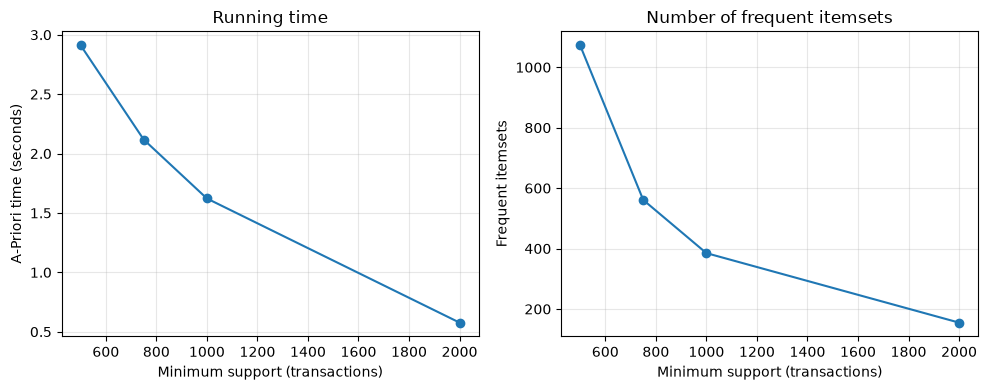

In [10]:
# 左图是运行时间，右图是频繁项集数量。横轴是支持度阈值。
supports = [row["support"] for row in sweep_rows]
figure, (time_axis, count_axis) = plt.subplots(1, 2, figsize=(10, 4))

time_axis.plot(supports, [row["apriori_seconds"] for row in sweep_rows], marker="o")
time_axis.set_xlabel("Minimum support (transactions)")
time_axis.set_ylabel("A-Priori time (seconds)")
time_axis.set_title("Running time")
time_axis.grid(True, alpha=0.3)

count_axis.plot(supports, [row["itemsets"] for row in sweep_rows], marker="o")
count_axis.set_xlabel("Minimum support (transactions)")
count_axis.set_ylabel("Frequent itemsets")
count_axis.set_title("Number of frequent itemsets")
count_axis.grid(True, alpha=0.3)

figure.tight_layout()
plt.show()

## 10. 结论

下面的数字来自本 Notebook 的这一次运行。运行环境是一台 macOS 笔记本电脑，Python 3.13，单进程，只使用标准库。运行时间会随电脑性能变化。

**`MIN_SUPPORT = 1000`、`MIN_CONFIDENCE = 0.6` 的结果**

- 数据集有 100,000 条交易、870 个不同的项目，读取用时 0.19 秒。
- A-Priori 找到 385 个频繁项集：375 个 1-项集、9 个 2-项集和 1 个 3-项集 `{39, 704, 825}`，支持度为 1035。总用时 1.45 秒。
- 生成 5 条关联规则，用时不到 0.001 秒。置信度最高的是 `{704, 825} -> {39}`，置信度 0.939。

| 层 | 候选项集 | 频繁项集 | 用时 |
|---:|---:|---:|---:|
| 1 | 870 | 375 | 0.24 s |
| 2 | 70,125 | 9 | 1.18 s |
| 3 | 1 | 1 | 0.02 s |
| 4 | 0 | 0 | 0.00 s |

第 2 层的时间最长。375 个频繁项目两两组合得到 70,125 个候选，每条交易平均约 10 个项目，要枚举约 45 个项目对。第 3 层只有 1 个候选。9 个频繁 2-项集能合并出两个 3-项集：`{368, 682, 829}` 的子集 `{682, 829}` 不频繁，在计数前就被剪掉，只剩下三个子集都频繁的 `{39, 704, 825}`。这正是 A-Priori 剪枝的作用。

**不同支持度阈值**

| 最小支持度 | 频繁项集 | 最大项集大小 | 候选项集总数 | 规则（c = 0.6） | A-Priori 用时 | 规则生成用时 |
|---:|---:|---:|---:|---:|---:|---:|
| 2000 | 155 | 1 | 12,805 | 0 | 0.58 s | < 0.001 s |
| 1000 | 385 | 3 | 70,996 | 5 | 1.62 s | < 0.001 s |
| 750 | 561 | 4 | 107,866 | 149 | 2.12 s | < 0.001 s |
| 500 | 1,073 | 5 | 162,690 | 1,072 | 2.91 s | 0.003 s |

支持度阈值越低，频繁的单个项目越多，第 2 层的候选数量随之按平方增长，同时出现更大的频繁项集，需要扫描更多层，所以运行时间上升。规则生成只使用已经算好的支持度，不再扫描交易，用时可以忽略。

**正确性**

`test_apriori.py` 在 200 个随机小数据集上把频繁项集和关联规则与暴力枚举的结果逐一比较，全部一致。第 2 节的四条交易可以人工核对。

## 11. AI Disclosure statement

本项目使用生成式 AI 协助理解作业要求、辅助梳理算法结构、整理文档和补充注释。最终代码由学生在本地数据集上运行、测试和检查，实验结果来自本地实际运行。数据集选择、参数选择、结果解释和最终提交内容由学生负责。